# **Maestría en Inteligencia Artificial Aplicada**
## **Curso: Operaciones de Aprendizaje Automático (TC5061)**
### Tecnológico de Monterrey
### Profesor titular: Dr. Iván Reyes Amezcua

## **Actividad Semana 3: Dataset - Notebook (Baseline ML)**

**Alumno:** Jesús Alejandro Juárez González

**Matrícula:** A01797889

**Dataset:** Ames Housing (OpenML, `house_prices`)


##0. Configuración del entorno

In [2]:
#Librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
import mlflow

In [3]:
#Definimos una semilla fija para que los datos puedan ser reproducibles
RANDOM_STATE = 42


## 1. Carga y descripción del dataset

## Descripción del dataset y justificación

Trabajamos con el conjunto de datos de precios de vivienda de Ames, Iowa, publicado por Dean De Cock (2011) en el *Journal of Statistics Education* y usado en la competencia de Kaggle *House Prices: Advanced Regression Techniques*. Lo cargamos desde OpenML con `fetch_openml`. Cada registro es una vivienda vendida en Ames entre 2006 y 2010.

Se elige este dataset porque plantea un problema de regresión supervisada con una variable objetivo continua y fácil de interpretar. Además mezcla variables numéricas y categóricas, tiene valores faltantes en varias columnas y su variable objetivo muestra asimetría.

In [4]:
#Cargamos el dataset de Ames Housing desde OpenML
data = fetch_openml("house_prices",as_frame=True)
type(data)


sklearn.utils._bunch.Bunch

In [5]:
#El dataset cargado viene en un bunch. Visualizamos los registros para seleccionar la tabla con la información completa.
data.keys()

dict_keys(['data', 'target', 'frame', 'categories', 'feature_names', 'target_names', 'DESCR', 'details', 'url'])

In [6]:
#Obtenemos el dataframe y lo guardamos en df
df = data.frame
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [7]:
r,c = df.shape
print(f"Rows:{r}, Columns:{c}")
print("----------------------")
df.info()
df.dtypes.value_counts()

Rows:1460, Columns:81
----------------------
<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    146

str        43
int64      35
float64     3
Name: count, dtype: int64

El conjunto tiene 1460 observaciones y 81 columnas, que incluyen un identificador (`Id`) y la variable objetivo `SalePrice`, el precio de venta en dólares

| Variable | Tipo | Descripción |
|---|---|---|
| SalePrice | Numérica continua | Precio de venta en dólares. Variable objetivo |
| OverallQual | Numérica ordinal (1-10) | Calidad general de materiales y acabados |
| GrLivArea | Numérica continua | Área habitable sobre el nivel del suelo (pies²) |
| TotalBsmtSF | Numérica continua | Área total del sótano (pies²) |
| GarageCars | Numérica discreta | Capacidad del garaje en número de autos |
| YearBuilt | Numérica discreta | Año de construcción |
| LotArea | Numérica continua | Superficie del terreno (pies²) |
| Neighborhood | Categórica nominal | Vecindario dentro de Ames (25 categorías) |
| MSSubClass | Numérica en el dataset, categórica en realidad | Código del tipo de vivienda (20 = una planta, 60 = dos plantas, etc.) |

In [8]:
#Observamos estadistica descriptiva de las variables
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


La salida de `info()` muestra 43 columnas de tipo `object`, 35 de tipo `int64` y 3 de tipo `float64`. Las tres columnas flotantes son `LotFrontage`, `MasVnrArea` y `GarageYrBlt`, y su tipo se debe a que contienen valores faltantes.

Varias columnas tienen valores nulos. En `PoolQC`, `MiscFeature`, `Alley`, `FireplaceQu` y `Fence` faltan la mayoría de los registros.Según la documentación de De Cock, en estas columnas el valor NA indica que la vivienda carece de alguna característica por ejemplo que no tiene alberca o chimenea. Para este caso lo trataremos como una categoría propia.

En `describe()`, `SalePrice` tiene una media cercana a 180,921 dólares y una mediana de 163,000. En este caso la media supera a la mediana por lo que la distribución tiene sesgo a la derecha. Aplicar una transformación logarítmica al objetivo puede mejorar el ajuste de modelos lineales.

## 2. Análisis EDA

Antes de limpiar los datos se cuentan los valores nulos por columna.

In [9]:
nulos = df.isnull().sum()
nulos = nulos[nulos > 0]
nulos = nulos.sort_values(ascending=False)

porcentaje = nulos / len(df) * 100
porcentaje = porcentaje.round(2)

tabla_nulos = pd.concat([nulos,porcentaje], axis=1, keys=["nulos", "porcentaje"])
tabla_nulos

,nulos,porcentaje
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageCond,81,5.55
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


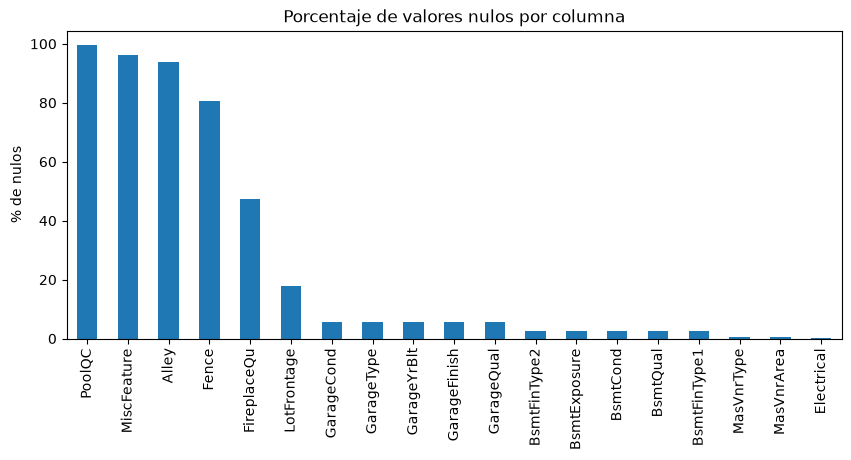

In [10]:
#Elaboramos gráfica para interpretación
porcentaje.plot(kind="bar", figsize=(10, 4))
plt.title("Porcentaje de valores nulos por columna")
plt.ylabel("% de nulos")
plt.show()

`PoolQC`, `MiscFeature`, `Alley` y `Fence` superan el 80% de valores nulos, mientras que la variable `FireplaceQu` también es prominente. Según la información del Dataset, un valor de nulo indica que la vivienda no tiene la característica marcada por la columna, por lo que se puede rellenar con la categoría de Ninguno.

Por otro lado tenemos varias columnas que corresponden al garage y otro grupo que corresponde al sótano.

`LotFrontage` es otra de las columnas relevantes donde hay valores que no fueron registrados. Es diferente a los primeras columnas porque esta categoría habla del frente de la casa. Todas las casas tienen frente, no es opcional como una piscina por ejemplo. Los valores ausentes deberán rellenarse en todo caso.



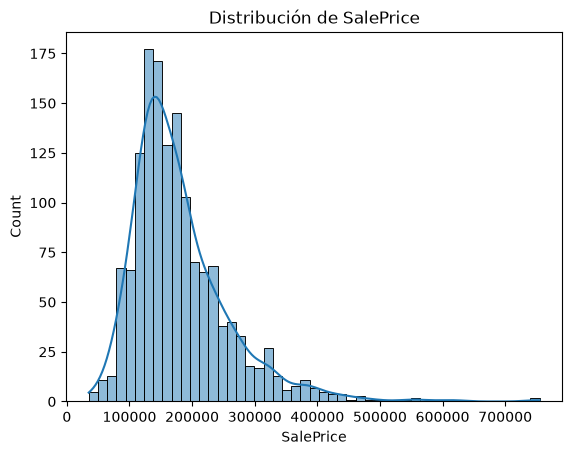

Asimetría: 1.8828757597682129


In [11]:
#Distribución del precio de venta
sns.histplot(data=df, x="SalePrice", kde=True)
plt.title("Distribución de SalePrice")
plt.show()
print("Asimetría:", df["SalePrice"].skew())

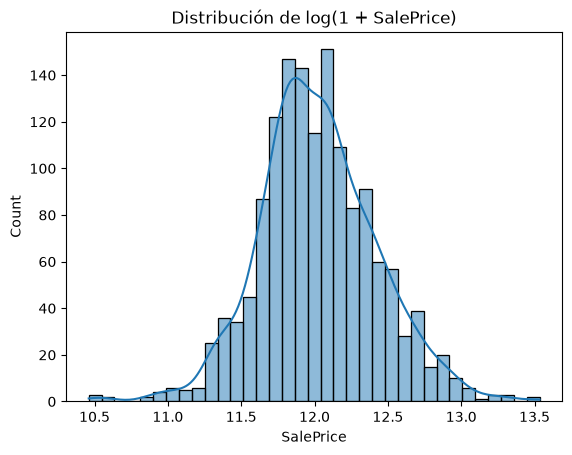

Asimetría: 0.12134661989685329


In [12]:
#Distribución del logaritmo del precio
log_precio = np.log1p(df["SalePrice"])
sns.histplot(x=log_precio, kde=True)
plt.title("Distribución de log(1 + SalePrice)")
plt.show()
print("Asimetría:", log_precio.skew())

`SalePrice` tiene asimetría positiva con un valor mayor a 1, de 1.88. Podemos decir que la mayoría de las casas se concentra entre 130,000 y 215,000 dólares, con una cola larga que llega a 755,000. Con la transformación `log1p` la asimetría baja un valor de 0.12 y la distribución se aproxima a una normal. Por eso usaremos el logaritmo del precio como objetivo del modelo lineal.

In [13]:
#Correlación de las variables numéricas con el precio
corr = df.corr(numeric_only=True)
corr["SalePrice"].sort_values(ascending=False).head(11)

SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
Name: SalePrice, dtype: float64

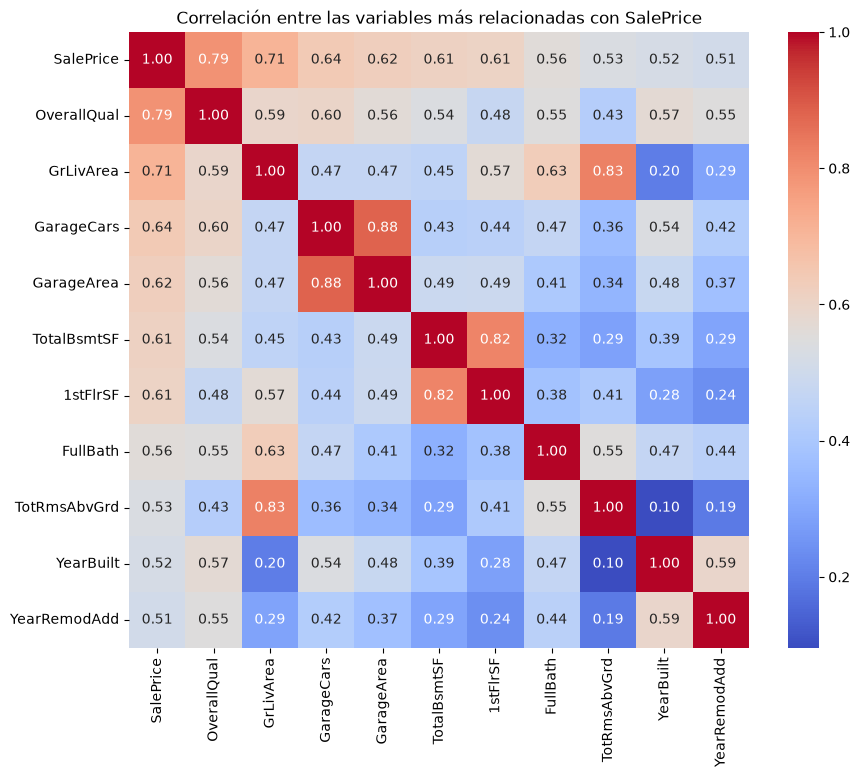

In [14]:
#Mapa de calor de las 10 variables más correlacionadas con SalePrice
top = corr["SalePrice"].sort_values(ascending=False).head(11).index
plt.figure(figsize=(10, 8))
sns.heatmap(df[top].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlación entre las variables más relacionadas con SalePrice")
plt.show()

Las variables más correlacionadas con `SalePrice` son `OverallQual` con 0.79, `GrLivArea` con un 0.71, `GarageCars` con 0.64, `GarageArea` con 0.62 y `TotalBsmtSF` con un 0.61.

El mapa de calor también muestra correlaciones como `GarageCars` y `GarageArea` con 0.88, `GrLivArea` y `TotRmsAbvGrd` con un 0.83, `TotalBsmtSF` y `1stFlrSF` con un valor de 0.82. Estos pares deben controlarese con un ridge.

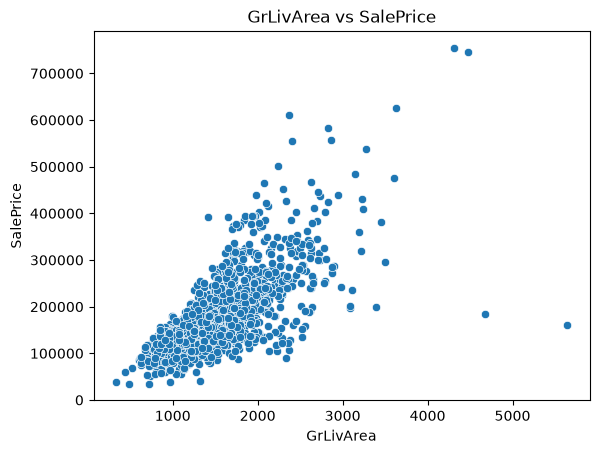

In [15]:
#Relación entre área habitable y precio
sns.scatterplot(data=df, x="GrLivArea", y="SalePrice")
plt.title("GrLivArea vs SalePrice")
plt.show()

La relación entre `GrLivArea` y `SalePrice` es positiva y aproximadamente lineal. Dos viviendas con más de 4,500 pies² se vendieron por menos de 200,000 dólares, muy por debajo de la tendencia. La información del dataset recomienda eliminar las casas con más de 4,000 pies² porque corresponden a ventas que salen del patrón.

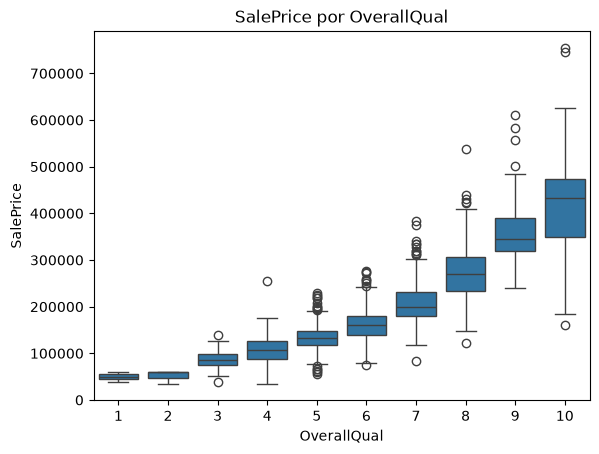

In [16]:
#Precio por calidad general
sns.boxplot(data=df, x="OverallQual", y="SalePrice")
plt.title("SalePrice por OverallQual")
plt.show()

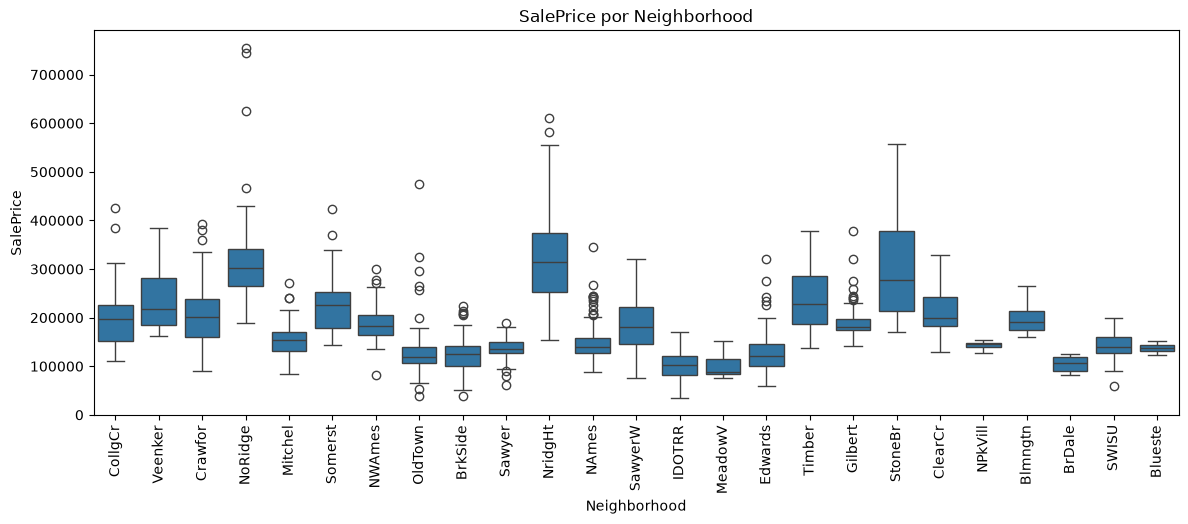

In [17]:
#Precio por vecindario
plt.figure(figsize=(14, 5))
sns.boxplot(data=df, x="Neighborhood", y="SalePrice")
plt.xticks(rotation=90)
plt.title("SalePrice por Neighborhood")
plt.show()

La mediana del precio aumenta de forma consistente con cada nivel de `OverallQual`, y la dispersión crece en los niveles 9 y 10. Por vecindario, `NoRidge` y `NridgHt` tienen las medianas más altas, mientras `MeadowV` e `IDOTRR` tienen las más bajas. La ubicación cambia el precio dependiendo de la región.

### Conclusiones del EDA

El precio depende principalmente de la calidad general, el área habitable y la ubicación. El objetivo requiere transformación logarítmica por su asimetría. La mayoría de los nulos representa ausencia de la característica y se tratará como categoría propia. La columna `LotFrontage` requiere imputación como explicado con anterioridad.

## 3. Limpieza de datos

In [18]:
#Eliminamos la columna de ID
df = df.drop(columns="Id")
#Revisamos filas duplicadas
# Revisamos filas duplicadas
print("Duplicados:", df.duplicated().sum())

Duplicados: 0


No hay filas duplicadas, así que no se elimina ningún registro por este motivo.

In [19]:
#MSSubClass es un código de tipo de vivienda y no una cantidad por lo que se convierte a texto
df["MSSubClass"] = df["MSSubClass"].astype(str)

`MSSubClass` está guardada como número, pero cada valor es un código de tipo de vivienda con números como 20, 60, o 190 por ejemplo. La convertimos a texto para que el modelo la trate como categoría.

In [20]:
#Columnas donde NA significa que la casa no tiene la característica
sin_caracteristica = ["PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
                      "GarageType", "GarageFinish", "GarageQual", "GarageCond",
                      "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
                      "MasVnrType"]
df[sin_caracteristica] = df[sin_caracteristica].fillna("Ninguno")

#Sin revestimiento de mampostería, el área es cero
df["MasVnrArea"] = df["MasVnrArea"].fillna(0)

In [21]:
#GarageYrBlt repite la información de YearBuilt
df = df.drop(columns="GarageYrBlt")

Eliminamos `GarageYrBlt` porque en las casas sin garaje no existe un año que poner, y el año de construcción ya lo aporta `YearBuilt`.

Casas eliminadas: 4


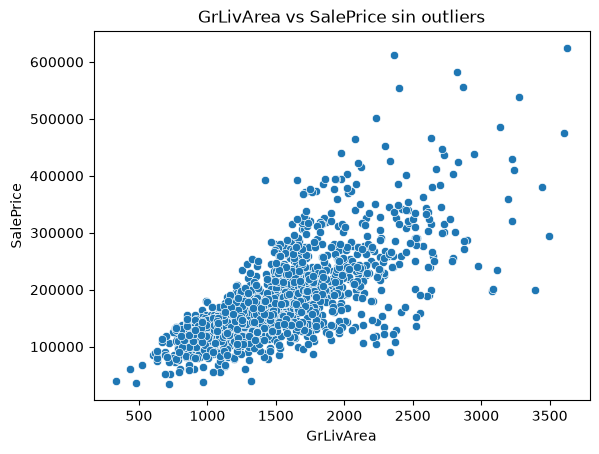

In [22]:
#Eliminamos las casas con más de 4,000 pies² habitables por recomendación de la documentación.
print("Casas eliminadas:", (df["GrLivArea"] > 4000).sum())
df = df[df["GrLivArea"] <= 4000]

#Verificamos la relación sin los outliers
sns.scatterplot(data=df, x="GrLivArea", y="SalePrice")
plt.title("GrLivArea vs SalePrice sin outliers")
plt.show()

In [23]:
#Dimensiones finales y nulos restantes
print("Dimensiones:", df.shape)
df.isnull().sum()[df.isnull().sum() > 0]

Dimensiones: (1456, 79)


LotFrontage    259
Electrical       1
dtype: int64

Quedan valores nulos en `LotFrontage` y `Electrical`. Son valores que no se registraron, así que se imputan con un valor calculado. Usaremos la mediana para `LotFrontage` y el valor más frecuente para `Electrical`.

## 4. División de datos y modelo base

In [24]:
#Separamos predictoras (X) y objetivo (y)
#El objetivo se transforma con log1p
X = df.drop(columns="SalePrice")
y = np.log1p(df["SalePrice"])

Separamos las predictoras del objetivo. Usamos el logaritmo del precio como objetivo porque en el EDA vimos que reduce la asimetría de 1.88 a 0.12.

In [25]:
#Utilizamos el 80% para entrenamiento y el 20% de prueba.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

Entrenamiento: (1164, 78)
Prueba: (292, 78)


In [26]:
#Separamos columnas numéricas y categóricas para darles tratamiento distinto
num_cols = X.select_dtypes(include="number").columns
cat_cols = X.select_dtypes(exclude="number").columns
print("Numéricas:", len(num_cols))
print("Categóricas:", len(cat_cols))

Numéricas: 34
Categóricas: 44


In [27]:
#Para las columnas numéricas: imputar con la mediana y escalar
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

#Para las columnas categóricas: imputar con el valor más frecuente y convertir a columnas 0/1
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

#Aplicamos cada tratamiento a su grupo de columnas
preprocesador = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)
])

In [28]:
#Baseline de referencia
dummy = DummyRegressor(strategy="median")
dummy.fit(X_train, y_train)

,"strategy strategy: {""mean"", ""median"", ""quantile"", ""constant""}, default=""mean""Strategy to use to generate predictions.* ""mean"": always predicts the mean of the training set* ""median"": always predicts the median of the training set* ""quantile"": always predicts a specified quantile of the training set, provided with the quantile parameter.* ""constant"": always predicts a constant value that is provided by the user.",'median'
,"constant constant: int or float or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
,"quantile quantile: float in [0.0, 1.0], default=NoneThe quantile to predict using the ""quantile"" strategy. A quantile of0.5 corresponds to the median, while 0.0 to the minimum and 1.0 to themaximum.",None
Name,Type,Value
"constant_ constant_: ndarray of shape (1, n_outputs)Mean or median or quantile of the training targets or constant valuegiven by the user.","ndarray[float64](1, 1)",[[12.01]]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X` hasfeature names that are all strings.","ndarray[object](78,)","['MSSubClass','MSZoning','LotFrontage',...,'YrSold','SaleType', 'SaleCondition']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`.,int,78
n_outputs_ n_outputs_: intNumber of outputs.,int,1


In [29]:
#Modelo base
modelo = Pipeline([
    ("preprocesador", preprocesador),
    ("ridge", Ridge(alpha=1.0))
])
modelo.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesador', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](78,)","['MSSubClass','MSZoning','LotFrontage',...,'YrSold','SaleType', 'SaleCondition']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,78
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset 

Elegimos Ridge como modelo base porque es una regresión lineal simple e interpretable, y su penalización controla la multicolinealidad que vimos en el mapa de calor.

## 5. Evaluación del modelo

In [30]:
#Predicciones en escala logarítmica, convertidas de vuelta a dólares con expm1
y_test_real = np.expm1(y_test)
pred_dummy = np.expm1(dummy.predict(X_test))
pred_ridge = np.expm1(modelo.predict(X_test))

In [31]:
#Métricas de ambos modelos sobre el conjunto de prueba
resultados = pd.DataFrame({
    "MAE": [mean_absolute_error(y_test_real, pred_dummy), mean_absolute_error(y_test_real, pred_ridge)],
    "RMSE": [root_mean_squared_error(y_test_real, pred_dummy), root_mean_squared_error(y_test_real, pred_ridge)],
    "R2": [r2_score(y_test_real, pred_dummy), r2_score(y_test_real, pred_ridge)]
}, index=["Dummy (mediana)", "Ridge"])
resultados.round(2)

,MAE,RMSE,R2
Dummy (mediana),54387.66,73250.31,-0.02
Ridge,14153.20,19976.40,0.92


In [32]:
#Comparamos R2 en entrenamiento y prueba para detectar sobreajuste
print("R2 entrenamiento:", round(r2_score(y_train, modelo.predict(X_train)), 3))
print("R2 prueba:", round(r2_score(y_test, modelo.predict(X_test)), 3))

R2 entrenamiento: 0.953
R2 prueba: 0.901


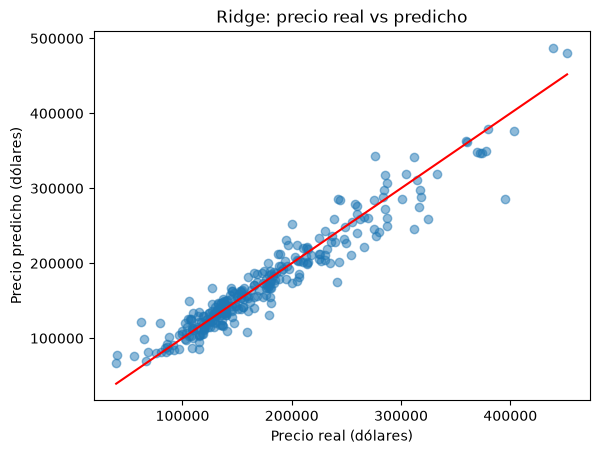

In [33]:
#Cada punto es una casa; la línea roja marca la predicción perfecta
plt.scatter(y_test_real, pred_ridge, alpha=0.5)
plt.plot([y_test_real.min(), y_test_real.max()], [y_test_real.min(), y_test_real.max()], color="red")
plt.xlabel("Precio real (dólares)")
plt.ylabel("Precio predicho (dólares)")
plt.title("Ridge: precio real vs predicho")
plt.show()

### Interpretación de resultados

Para ridge se obtiene un MAE de 14,161 dólares. En promedio, su predicción se desvía unos 14,000 dólares del precio real, cerca del 8.7% del precio mediano de una casa en Ames.

El R² de Ridge es 0.92. El modelo tonto tiene un R² de −0.02 porque no usa ninguna característica de la casa y siempre predice la mediana.

El RMSE es mayor que el MAE, lo que indica que en algunas casas el error es grande. La gráfica muestra que las predicciones se dispersan en las casas más caras.

El R² de entrenamiento es un poco mayor que el de prueba. La diferencia indica un pequeño sobreajuste.

## 6. Registro del experimento en MLflow

In [34]:
# Guardamos el registro de experimentos en una base SQLite local
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("TC5061_Baseline_AmesHousing")

2026/10/10 08:16:16 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/10 08:16:16 INFO mlflow.store.db.utils: Updating database tables
2026/10/10 08:16:21 INFO mlflow.tracking.fluent: Experiment with name 'TC5061_Baseline_AmesHousing' does not exist. Creating a new experiment.


<Experiment: artifact_location='/home/jandro/proyectos/mlops-tc5061/semana4-mlflow/notebooks/mlruns/1', creation_time=1791641781044, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1791641781044, lifecycle_stage='active', name='TC5061_Baseline_AmesHousing', tags={}, trace_location=None, workspace='default'>

In [35]:
# Run del modelo base Ridge con sus parámetros y métricas
with mlflow.start_run(run_name="ridge_baseline"):
    mlflow.log_param("modelo", "Ridge")
    mlflow.log_param("alpha", 1.0)
    mlflow.log_param("test_size", 0.2)
    mlflow.log_param("random_state", RANDOM_STATE)
    mlflow.log_param("objetivo", "log1p(SalePrice)")
    mlflow.log_param("outliers", "GrLivArea > 4000 eliminados")
    mlflow.log_metric("mae", mean_absolute_error(y_test_real, pred_ridge))
    mlflow.log_metric("rmse", root_mean_squared_error(y_test_real, pred_ridge))
    mlflow.log_metric("r2", r2_score(y_test_real, pred_ridge))
    mlflow.log_metric("r2_train_log", r2_score(y_train, modelo.predict(X_train)))
    mlflow.log_metric("r2_test_log", r2_score(y_test, modelo.predict(X_test)))

Registramos el modelo base en el experimento `TC5061_Baseline_AmesHousing`.

### Evidencia del registro en MLflow

La interfaz de MLflow muestra el run `ridge_baseline` con sus parámetros y métricas, entre ellas un MAE de 14,161 dólares y un R² de 0.92.

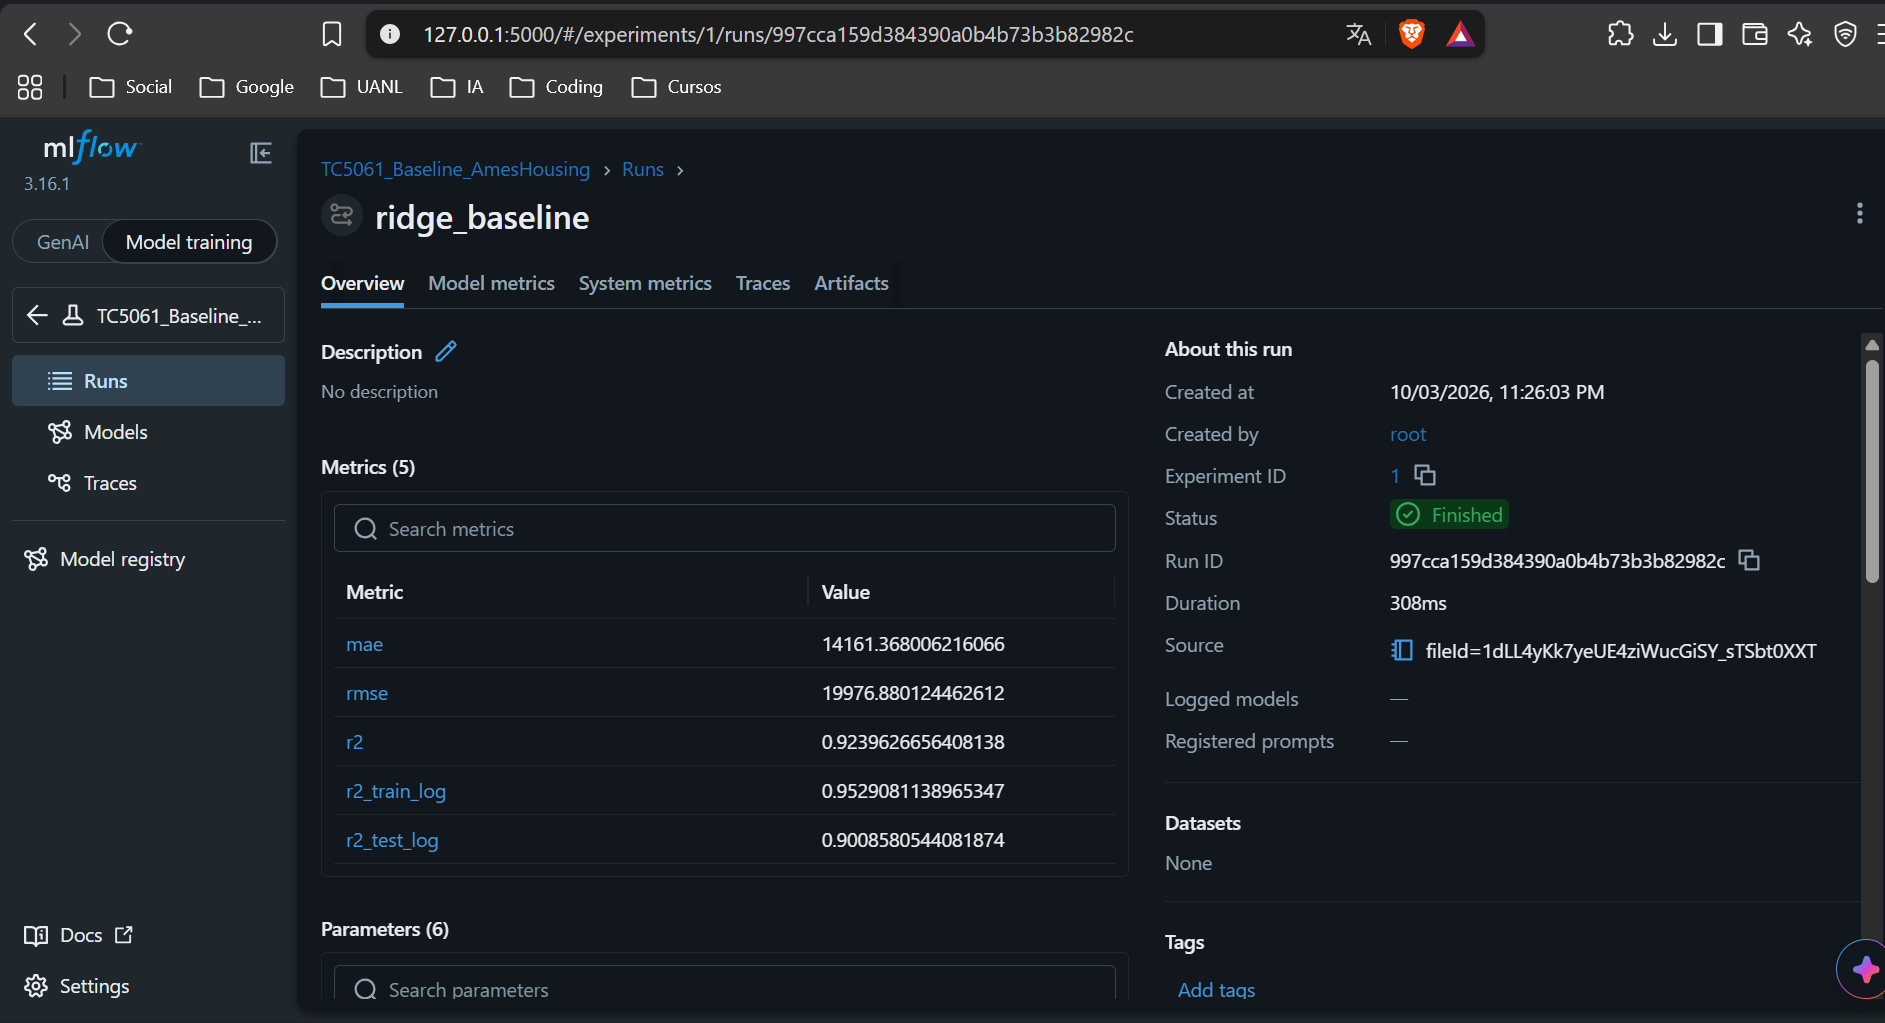

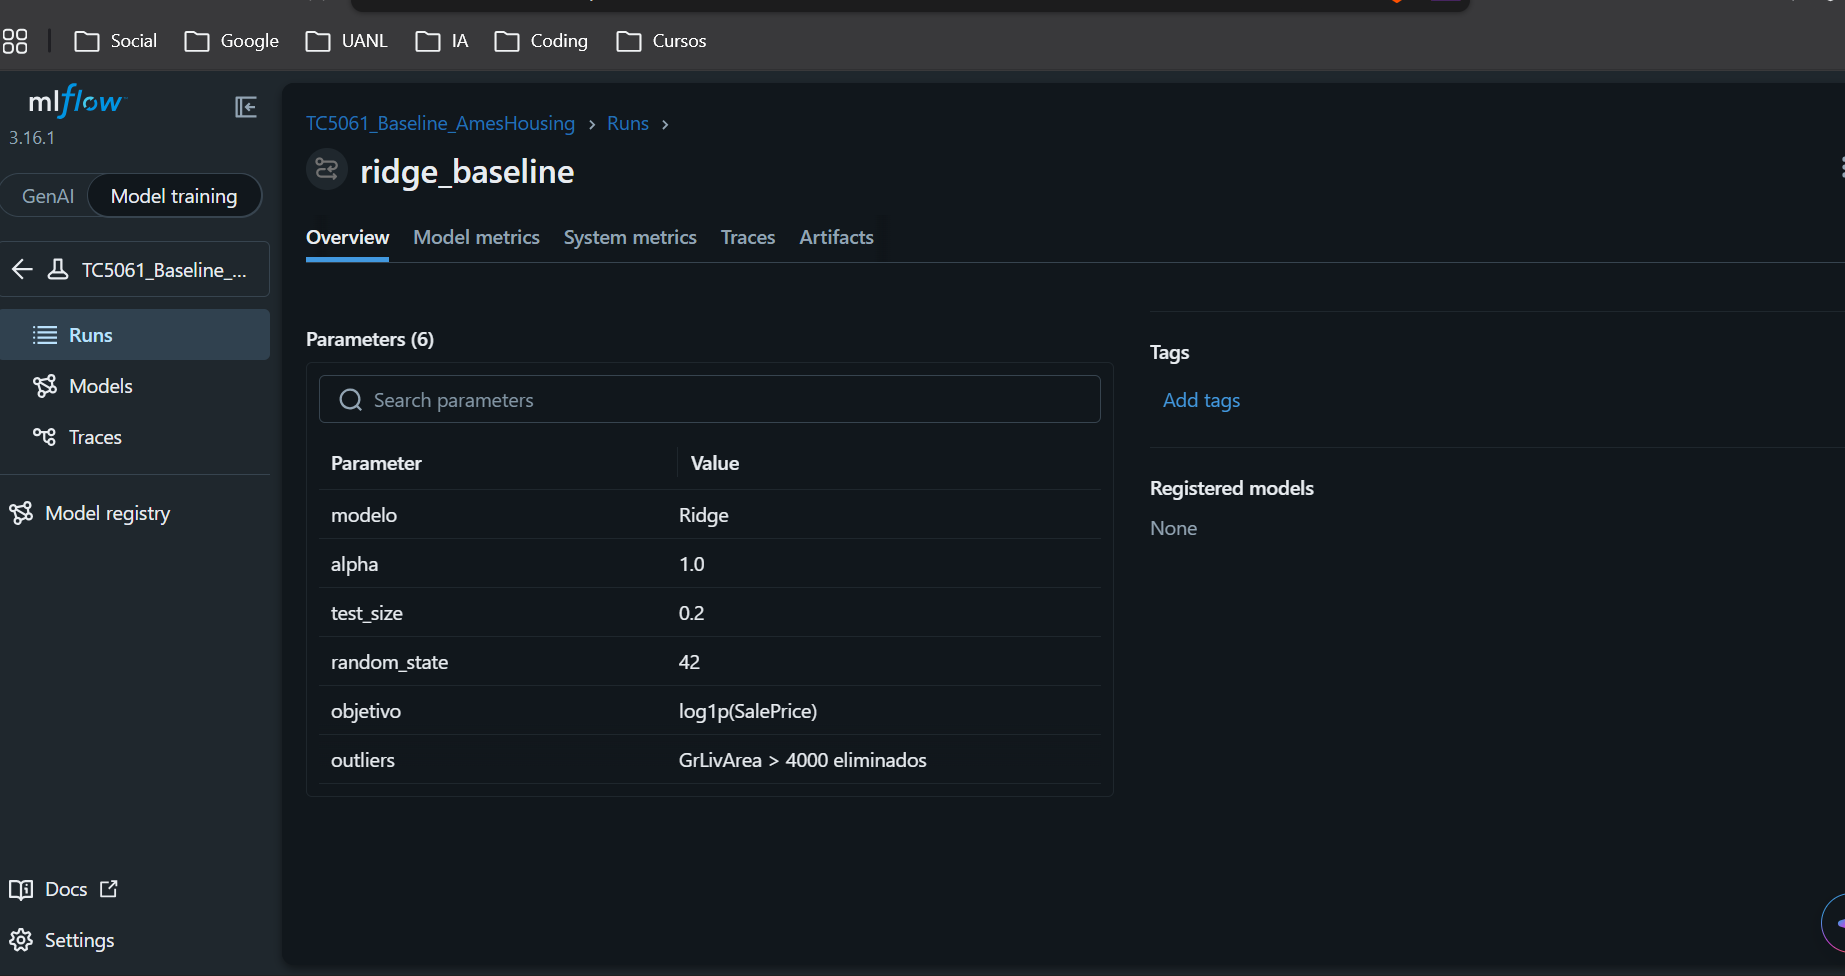

## 7. Reflexión sobre MLOps

Lo primero que mejoraría es fijar las versiones de las librerías en un archivo `requirements.txt`. Durante la actividad, MLflow cambió su formato por defecto para guardar modelos de scikit-learn y el registro del pipeline falló con un error nuevo.

También pasaría el código del notebook a scripts dentro de una estructura como Cookiecutter Data Science. Para obtener un registro limpio tuve que borrar el entorno y ejecutar todo otra vez. Con funciones separadas para los procesos de carga, limpieza, entrenamiento y evaluación, cada parte se puede probar con PyTest.

El modelo presenta un sobreajuste aparente, con un R² de 0.953 en entrenamiento con respecto a un 0.901 en la prueba. El siguiente paso sería el de registrar varias pruebas con distintos valores de alpha y comparar en MLflow.

Por último, este modelo fue elegido ya que mi trabajo se centra en el área inmobiliaria. Hoy cotizamos los lotes en venta con un simulador básico en Excel. Un modelo entrenado con las características de nuestros desarrollos pasados y el historial de ventas podría dar pie a sugerir un precio de referencia a futuro.

Para usarlo en la operación tendría que reentrenarse conforme entran ventas nuevas y monitorearse para detectar cambios en el mercado, prácticas que el curso cubre en el módulo 3.